In [1]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch
anaDir='./wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/'
dbDir='./wrkDir/database/s19_COSMOS/'

Populating the interactive namespace from numpy and matplotlib


# 3 catalogs

We use photo-z from three catalogs, which are:

* HSC wdie_depth_best catalog (S16A sim)
* HSC COSMOS WIDE catalog
* HST COSMOS photo-z 2015 catalog

In [3]:
dd1=pyfits.getdata('/work/xiangchong.li/work/galsim_train/real_galaxy_catalog_best_fits.fits')
dd2=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE.fits'))
ra=dd1['RA']
dec=dd1['DEC']
mask=(~np.isnan(dd2['mizuki_photoz_best']))
dd2=dd2[mask]
dd3=pyfits.getdata('/work/xiangchong.li/work/COSMOS/COSMOS2015_Laigle+_v1.1.fits.gz')
mask=(~np.isnan(dd3['PHOTOZ']))
mask=mask&((dd3['PHOTOZ']>0)&(dd3['PHOTOZ']<8))
dd3=dd3[mask]

In [13]:
match2   =   smatch.match(dd2['i_ra'],dd2['i_dec'],0.5/3600.,ra,dec,maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
match3   =   smatch.match(dd3['ALPHA_J2000'],dd3['DELTA_J2000'],0.5/3600.,ra,dec,maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
matMsk2=np.zeros(len(ra),dtype=bool)
matMsk2[match2['i2']]=True
matdd2=dd2[match2['i1']]
matMsk3=np.zeros(len(ra),dtype=bool)
matMsk3[match3['i2']]=True

In [15]:
np.percentile(dd3['PHOTOZ'][match3['i1']],np.linspace(0,100,4))

array([4.99999989e-03, 7.24099994e-01, 1.28779995e+00, 5.99490023e+00])

94.0774213819042 percent of galaxies in HSC WIDE


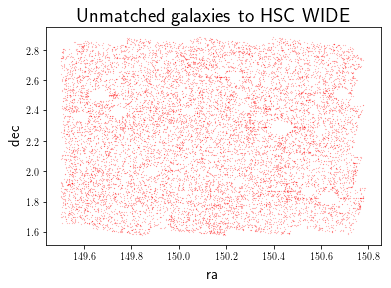

In [44]:
plt.scatter(ra[~matMsk2],dec[~matMsk2],s=0.01,c='red')
plt.title('Unmatched galaxies to HSC WIDE',fontsize=20)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
print('%s percent of galaxies in HSC WIDE' %(len(match2)/len(ra)*100.))

79.00437100902849 percent of galaxies in COSMOS 2015


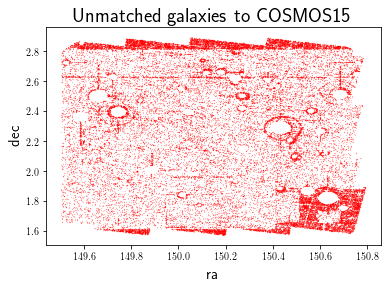

In [45]:
plt.scatter(ra[~matMsk3],dec[~matMsk3],s=0.01,c='red')
plt.title('Unmatched galaxies to COSMOS15',fontsize=20)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
print('%s percent of galaxies in COSMOS 2015' %(len(match3)/len(ra)*100.))

9.327899605407854 percent of galaxies in HSC WIDE (clipped)


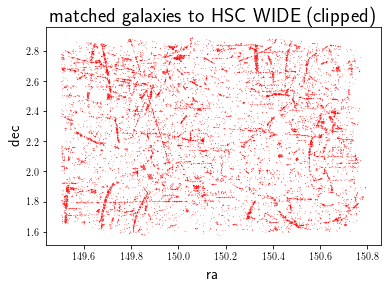

In [57]:
raU=ra[matMsk2]
decU=dec[matMsk2]
maskX=(matdd2['i_pixelflags_clipped'])
plt.scatter(raU[maskX],decU[maskX],s=0.01,c='red')
plt.title('matched galaxies to HSC WIDE (clipped)',fontsize=20)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
print('%s percent of galaxies in HSC WIDE (clipped)' %(np.sum(maskX)/len(ra)*100.))

# Match to COSMOS photo-z

In [ ]:
# Read the COSMOS catalog
cosmoname= '/work/xiangchong.li/work/galsim_train/COSMOS_25.2_training_sample/real_galaxy_catalog_25.2_fits.fits' 
assert os.path.isfile(cosmoname)
cosmocat=astTable.Table.read(cosmoname)
for fieldname in utilities.field_names:
    simFname=   os.path.join(anaDir,'%s/%s.fits' %(fieldname,fieldname))
    assert os.path.isfile(simFname)
    
    simDat=astTable.Table.read(simFname)
    catOut=astTable.join(simDat,cosmocat,'IDENT','left')
    # Make sure the index is the same as the origin catalog
    catOut.sort(['isim','paired','ipos'])
    outFname=os.path.join(anaDir,'%s/%s-2.fits' %(fieldname,fieldname))  
    catOut.write(outFname,overwrite=True)

False


False


False


False


# Match to HSC photo-z

In [2]:
hscCname=os.path.join(dbDir,'COSMOS_WIDE.fits')
hscCat=pyfits.getdata(hscCname)
print(len(hscCat))

917739


In [3]:
mask=(~np.isnan(hscCat['mizukiv2_photoz_best']))
hscCat=hscCat[mask]
print(len(hscCat))
zdnn=hscCat['dnnzv2_photoz_best']
zmizuki=hscCat['mizukiv2_photoz_best']
zdp=hscCat['dempv2_photoz_best']
ra=hscCat['i_ra']
dec=hscCat['i_dec']

917739


(array([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        3.7670e+03, 2.4320e+03, 1.0600e+03, 1.2760e+03, 1.8030e+03,
        8.3070e+03, 1.3852e+04, 2.5977e+04, 3.1761e+04, 2.8577e+04,
        2.0979e+04, 1.5440e+04, 2.0215e+04, 2.5970e+04, 1.6071e+04,
        7.4440e+03, 2.6310e+03, 1.1390e+03, 9.5500e+02, 1.5480e+03,
        3.5610e+03, 5.7660e+03, 9.0920e+03, 1.59

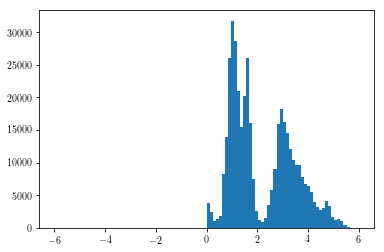

In [5]:
plt.hist((zdnn-zmizuki)[hscCat['i_cmodel_mag']<24.5],range=(-6,6),bins=100)

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in less
  This is separate from the ipykernel package so we can avoid doing imports until


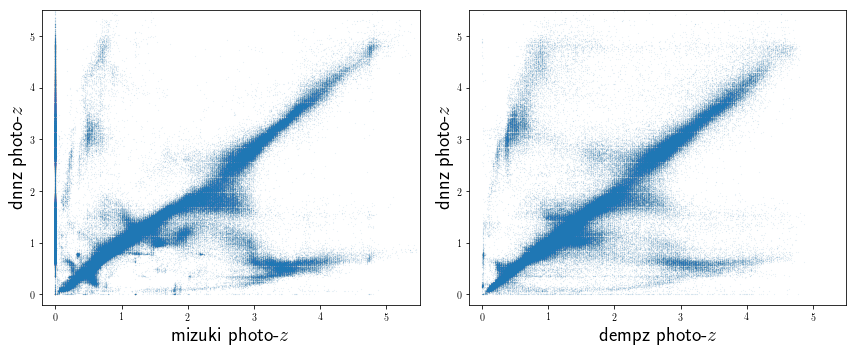

In [19]:
fig=plt.figure(figsize=(12,5))

ax=fig.add_subplot(1,2,1)
mask=hscCat['i_cmodel_mag']<25.2
plt.scatter(zmizuki[mask],zdnn[mask],s=0.001)
plt.xlabel(r'mizuki photo-$z$',fontsize=20)
plt.ylabel(r'dnnz photo-$z$',fontsize=20)
plt.xlim(-0.2,5.5)
plt.ylim(-0.2,5.5)

ax=fig.add_subplot(1,2,2)
plt.scatter(zdp[mask],zdnn[mask],s=0.001)
plt.xlabel(r'dempz photo-$z$',fontsize=20)
plt.ylabel(r'dnnz photo-$z$',fontsize=20)
plt.xlim(-0.2,5.5)
plt.ylim(-0.2,5.5)
plt.tight_layout()

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in less
  after removing the cwd from sys.path.


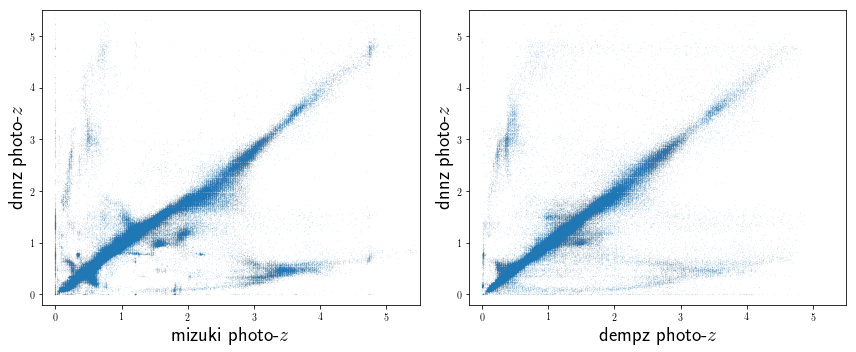

In [20]:
fig=plt.figure(figsize=(12,5))

ax=fig.add_subplot(1,2,1)
mask=hscCat['i_cmodel_mag']<24.5
plt.scatter(zmizuki[mask],zdnn[mask],s=0.001)
plt.xlabel(r'mizuki photo-$z$',fontsize=20)
plt.ylabel(r'dnnz photo-$z$',fontsize=20)
plt.xlim(-0.2,5.5)
plt.ylim(-0.2,5.5)

ax=fig.add_subplot(1,2,2)
plt.scatter(zdp[mask],zdnn[mask],s=0.001)
plt.xlabel(r'dempz photo-$z$',fontsize=20)
plt.ylabel(r'dnnz photo-$z$',fontsize=20)
plt.xlim(-0.2,5.5)
plt.ylim(-0.2,5.5)
plt.tight_layout()

In [5]:
if False:
    for fieldname in utilities.field_names:
        print('begin field: %s' %fieldname)
        simFname=   os.path.join(anaDir,'%s/%s.fits' %(fieldname,fieldname))
        assert os.path.isfile(simFname)
        simDat=astTable.Table.read(simFname)
        match   =   smatch.match(ra,dec,0.5/3600.,\
            simDat['RA'],simDat['DEC'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
        izbest=np.zeros(len(simDat))
        izbest[:]=np.NaN
        izbest[match['i2']]=zbest[match['i1']]
        simDat['mizuki_photoz_best']=izbest
        simDat.write(simFname,overwrite=True)
        print('finish field: %s' %fieldname)

In [6]:
simFname=   os.path.join(anaDir,'allSim.h5')
assert os.path.isfile(simFname)
simDat=pd.read_hdf(simFname,mode='a')
match   =   smatch.match(ra,dec,0.5/3600.,simDat['COSMOS_RA'],simDat['COSMOS_DEC'],maxmatch=1)

In [7]:
print(simFname)

./wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/allSim.h5


In [8]:
# For a galaxy in sim find the closest one in HSC Wide field
izm=np.zeros(len(simDat));izm[:]=np.NaN
izm[match['i2']]=zmizuki[match['i1']]
izd=np.zeros(len(simDat));izd[:]=np.NaN
izd[match['i2']]=zdnn[match['i1']]
izp=np.zeros(len(simDat));izp[:]=np.NaN
izp[match['i2']]=zdp[match['i1']]

simDat['mizuki_Z']=izm
simDat['dnn_Z']=izd
simDat['demp_Z']=izp

In [9]:
print(np.sum(~np.isnan(simDat['dnn_Z']))/len(simDat))
simDat.to_hdf(simFname,key='data')

0.9617380751683466


# Match to New COSMOS photo-z

In [2]:
cosmoName='/work/xiangchong.li/work/COSMOS/COSMOS2015_Laigle+_v1.1.fits.gz'
cosmoCat=pyfits.getdata(cosmoName)
mask=(~np.isnan(cosmoCat['PHOTOZ']))
mask=mask&((cosmoCat['PHOTOZ']>0)&(cosmoCat['PHOTOZ']<8))
cosmoCat=cosmoCat[mask]

In [3]:
ra=cosmoCat['ALPHA_J2000']
dec=cosmoCat['DELTA_J2000']
zbest=cosmoCat['PHOTOZ']

In [4]:
for fieldname in utilities.field_names:
    print('begin field: %s' %fieldname)
    simFname=   os.path.join(anaDir,'%s/%s-2.fits' %(fieldname,fieldname))
    assert os.path.isfile(simFname)
    simDat=astTable.Table.read(simFname)
    match   =   smatch.match(ra,dec,0.5/3600.,\
        simDat['RA'],simDat['DEC'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
    izbest=np.zeros(len(simDat))
    izbest[:]=np.NaN
    izbest[match['i2']]=zbest[match['i1']]
    simDat['COSMOS15_Z']=izbest
    simDat.write(simFname,overwrite=True)
    print('finish field: %s' %fieldname)

begin field: XMM


finish field: XMM
begin field: GAMA09H
finish field: GAMA09H
begin field: WIDE12H
finish field: WIDE12H
begin field: GAMA15H
finish field: GAMA15H
begin field: VVDS
finish field: VVDS
begin field: HECTOMAP
finish field: HECTOMAP


In [ ]:
print(np.sum(~np.isnan(simDat['COSMOS15_Z']))/len(simDat))